In [1]:
from visualize import *
from data_generation import *   
from preprocessing import *
from sb import loss
from sb import model
from datasets.dataset import *
from torch.utils.data import DataLoader
import torch.nn.functional as F

In [2]:
high_resol_coef = 0.01 # 점성 계수 작게
low_resol_coef = 0.1 # 점성 계수 크게

high_f_1d = generate_dataset(n_samples=40, nu=high_resol_coef, Nx=512, Nt=512, T=1.0, L=1.0, seed=0, warmup_steps=100)
print("GT high PDE (before downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
high_f_1d = high_f_1d[:,:,::4,::4]
low_f_1d = generate_dataset(n_samples=40, nu=low_resol_coef, Nx=128, Nt=128, T=1.0, L=1.0, U0=high_f_1d[:,:,[0], :], seed=20)
print("GT low PDE (after downsampling) :", loss.burgers_residual(torch.tensor(low_f_1d), low_resol_coef), "GT high PDE (after downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
# low_f_1d, high_f_1d = make_paired_time_window_dataset(low_f_1d, high_f_1d, win_T=128, stride=128)
# print("GT low PDE (after downsampling) :", loss.burgers_residual(torch.tensor(low_f_1d), low_resol_coef), "GT high PDE (after downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
mask_low_1d = make_sensor_mask(low_f_1d, n_sensors=13, sparse_ratio=None, seed=0)
mask_high_1d = make_sensor_mask(high_f_1d, n_sensors=13, sparse_ratio=None, seed=0)
high_filled = bicubic_fill_xy(high_f_1d, mask_high_1d)

# dataset_visualization(low_f_1d, mask_low_1d, batch_idx=0)
# dataset_visualization(high_f_1d, mask_high_1d, batch_idx=0)

100%|██████████| 40/40 [00:01<00:00, 27.36it/s]


GT high PDE (before downsampling) : tensor(0.0004)


100%|██████████| 40/40 [00:00<00:00, 196.55it/s]


GT low PDE (after downsampling) : tensor(0.0490) GT high PDE (after downsampling) : tensor(0.0590)


100%|██████████| 40/40 [00:00<00:00, 70.73it/s]


In [3]:
N = low_f_1d.shape[0]
train_ratio = 0.8
val_ratio = 0.1

N_train = int(N * train_ratio)
N_val = int(N * val_ratio)
N_test = N - N_train - N_val

low_train  = low_f_1d[:N_train]
high_train = high_f_1d[:N_train]
filled_train = high_filled[:N_train]
mask_train = mask_high_1d[:N_train]

low_val  = low_f_1d[N_train:N_train + N_val]
high_val = high_f_1d[N_train:N_train + N_val]
filled_val = high_filled[N_train:N_train + N_val]
mask_val = mask_high_1d[N_train:N_train + N_val]

low_test  = low_f_1d[N_train + N_val:]
high_test = high_f_1d[N_train + N_val:]
filled_test = high_filled[N_train + N_val:]
mask_test = mask_high_1d[N_train + N_val:]

ds_train = PDEPairDataset(low_data=low_train, high_data=high_train, mask_low_data=None, mask_high_data=mask_train)
dl_train = DataLoader(ds_train, batch_size=8, shuffle=False, drop_last=False)

ds_val = PDEPairDataset(low_data=low_val, high_data=high_val, mask_low_data=None, mask_high_data=mask_val)
dl_val = DataLoader(ds_val, batch_size=4, shuffle=False, drop_last=False)

ds_test = PDEPairDataset(low_data=low_test, high_data=high_test, mask_low_data=None, mask_high_data=mask_test)
dl_test = DataLoader(ds_test, batch_size=4, shuffle=False, drop_last=False)

In [4]:
sb_object = model.SB_model_ver1(train_dataloader=dl_train, val_dataloader=dl_val, timepoints=[0,1], time_dim=8, steps=10, base_lr=1e-4, save=True, pde_type='burgers')

In [5]:
sb_object.train(train_epochs=100000, model_name='40sample_try_known_alpha4.pt', known_alpha=0.01)

Train (1 batch per epoch):   0%|          | 0/100000 [00:16<?, ?it/s]


KeyboardInterrupt: 

In [5]:
models_dict=torch.load('./model/40sample_try_known_alpha3.pt')
sb_object.v_fore.load_state_dict(models_dict['v_fore'])
sb_object.time_embed.load_state_dict(models_dict['time_embed'])
# sb_object.optimizer_fore.load_state_dict(models_dict['optimizer_fore'])
# print(models_dict['alpha'])
# print(models_dict['best_val_pde'])
# loss_history = print(models_dict['loss_history'])       

<All keys matched successfully>

100%|██████████| 40/40 [00:00<00:00, 186.51it/s]


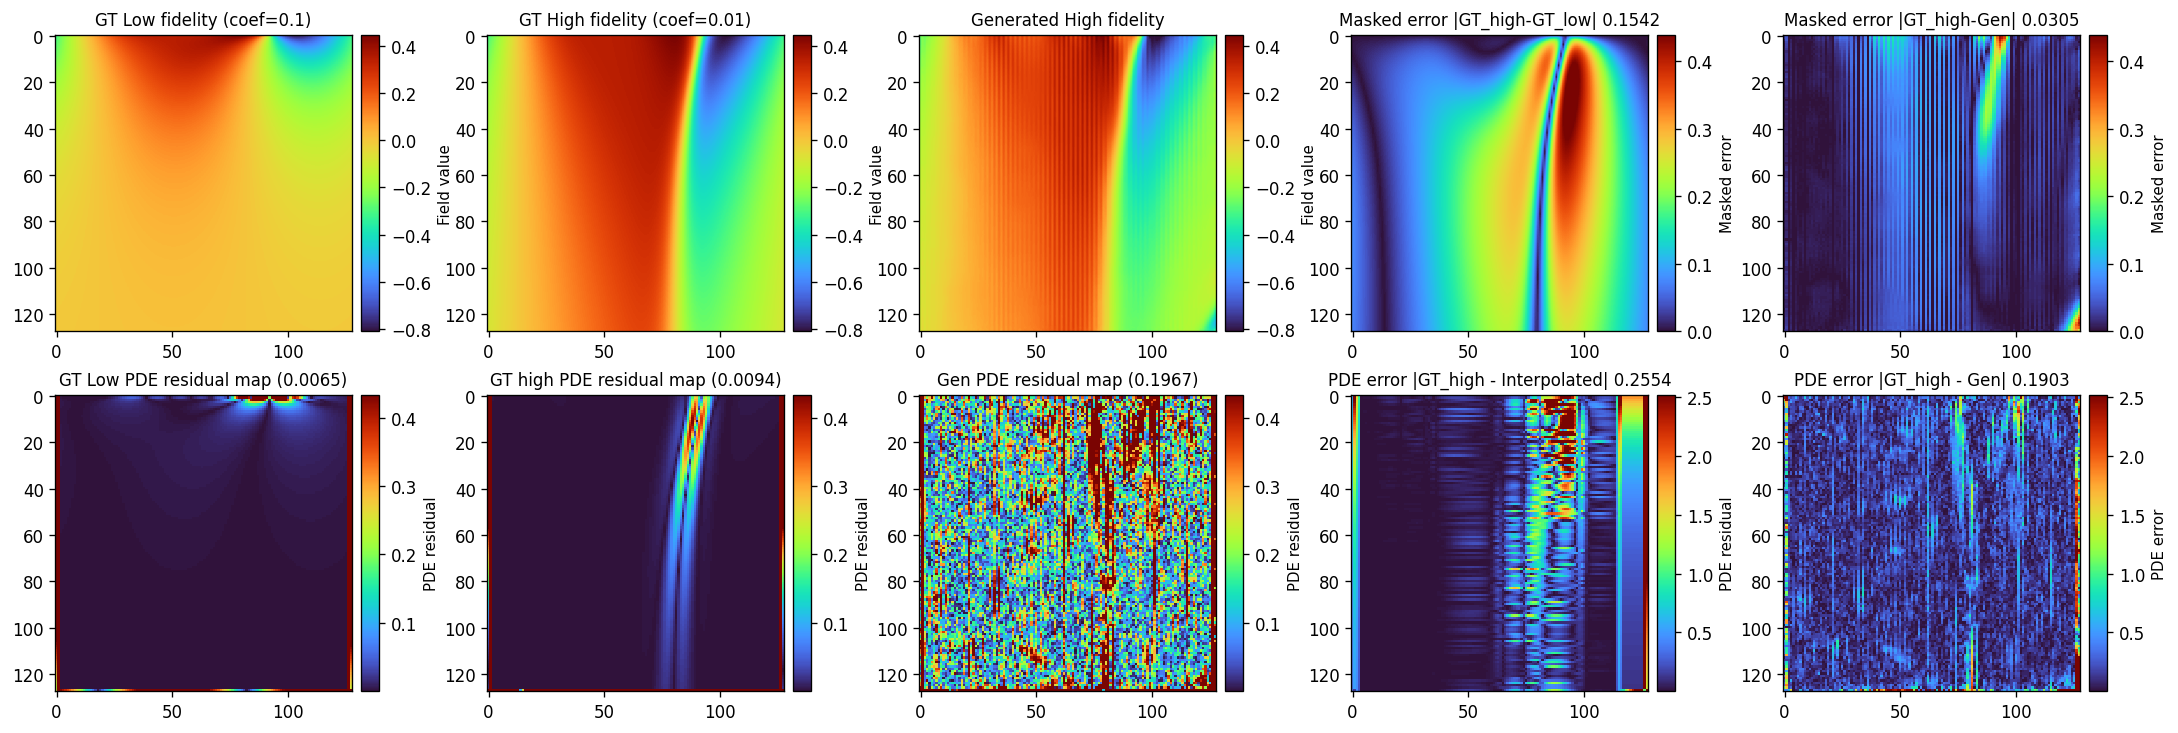

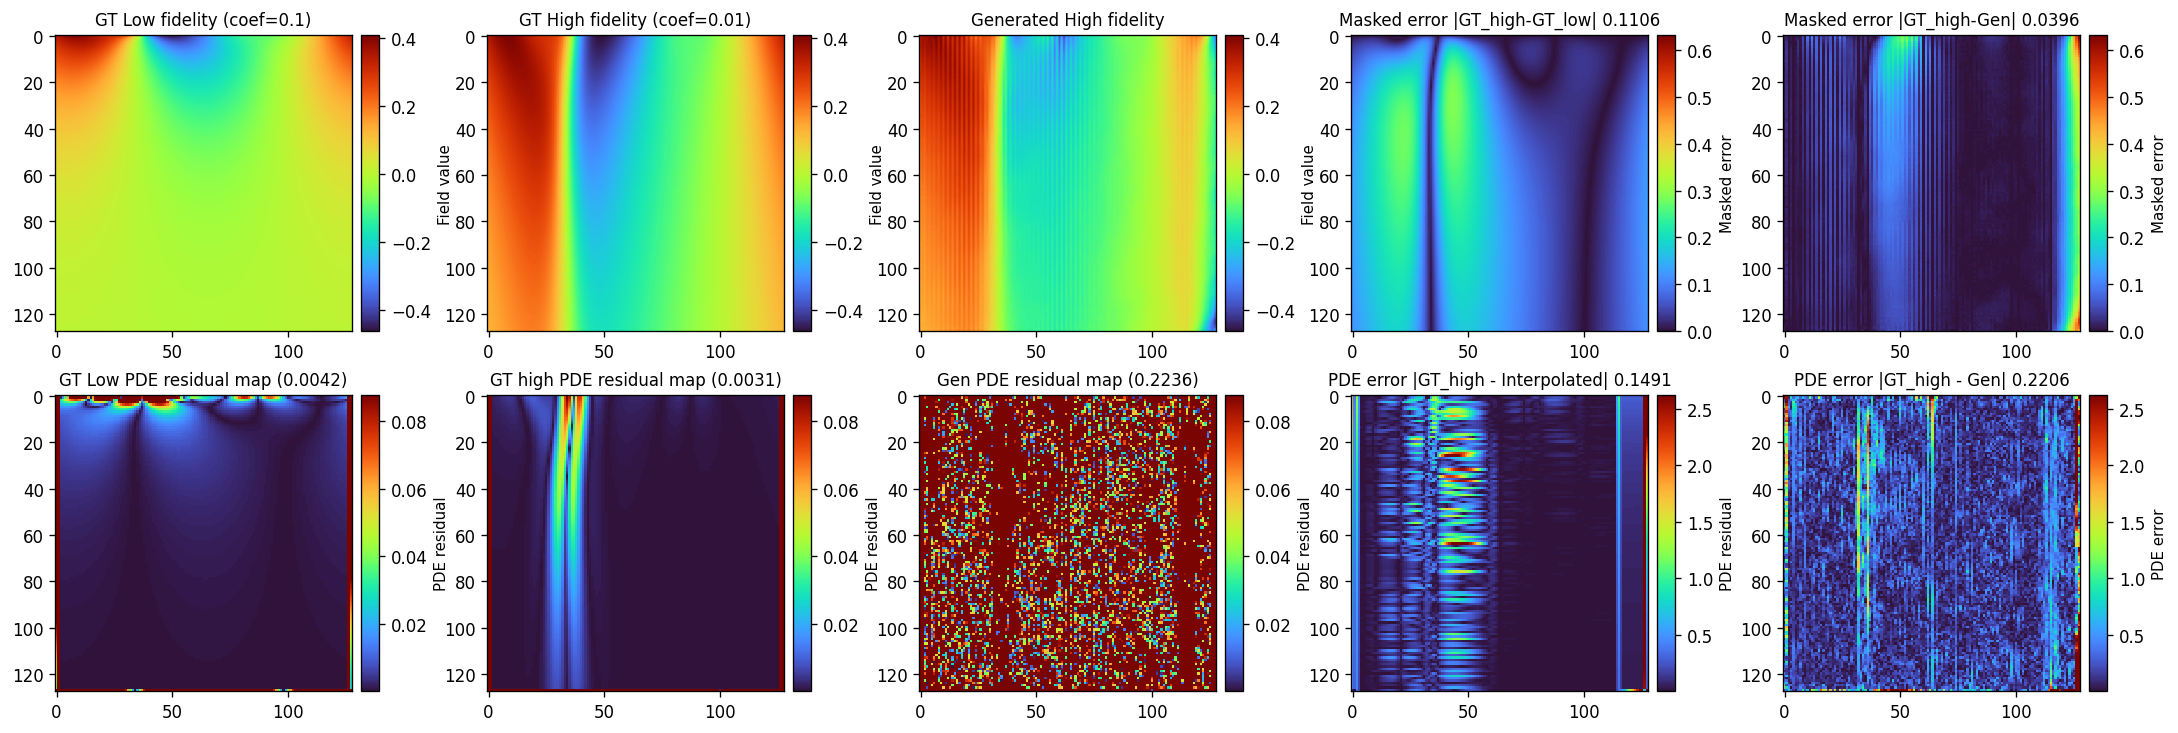

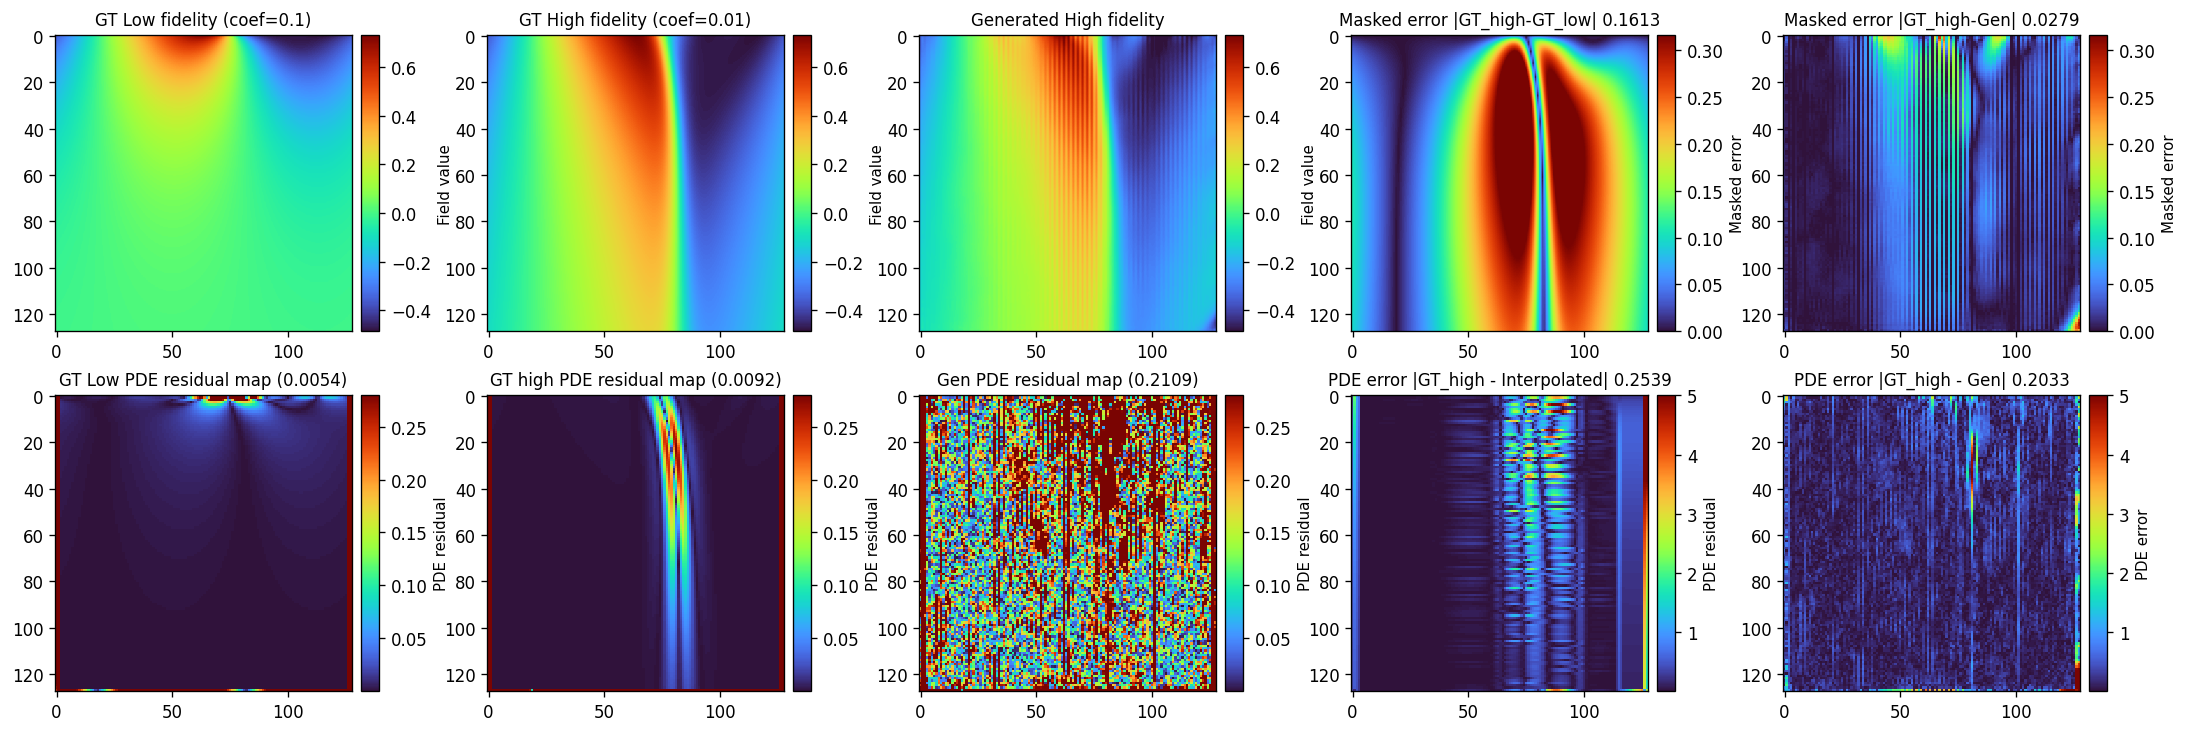

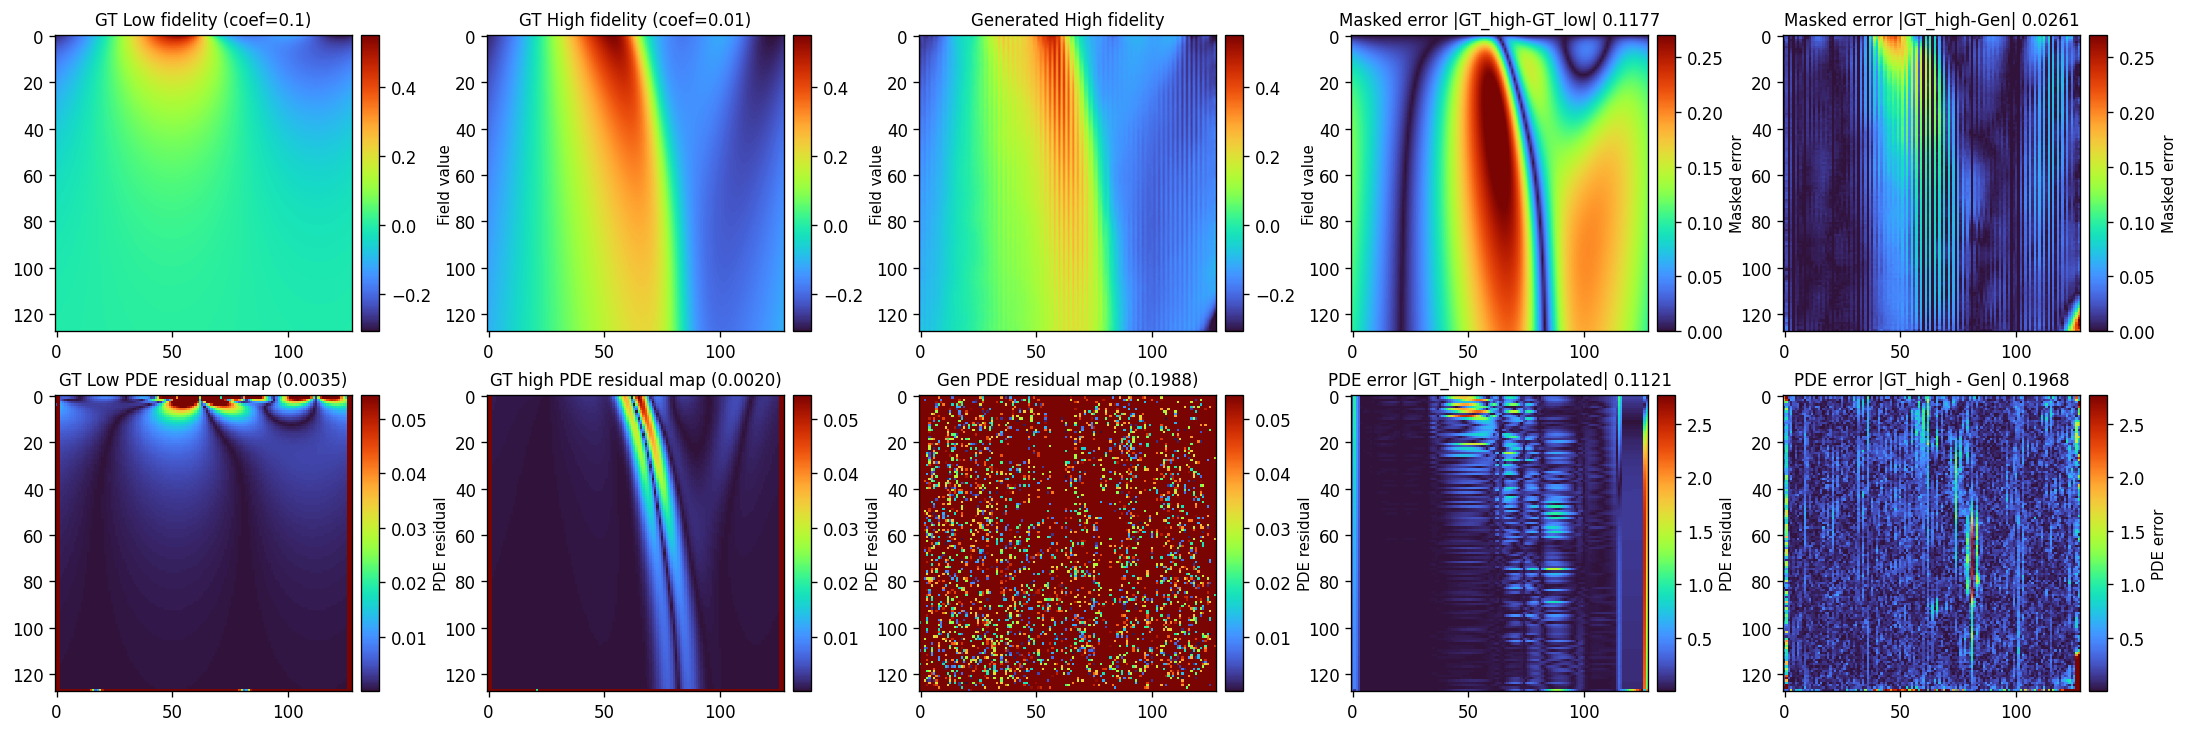

In [7]:
inference_target = 'test'

if inference_target == 'train':
    infer_filled = filled_train
    infer_dl = dl_train
elif inference_target == 'val':
    infer_filled = filled_val
    infer_dl = dl_val
else:
    infer_filled = filled_test
    infer_dl = dl_test
sb_object.v_fore.eval()
sb_object.time_embed.eval()

x0_chunks = []
m0_chunks = []
x1_chunks = []
m1_chunks = []
filled_chunks = []
ptr = 0
pred_chunks = []
with torch.no_grad():
    for x_0, x_1, mask_low, mask_high in infer_dl:
        B = x_0.size(0)
        pred = sb_object.eval_fore(x_0=x_0, x_1=x_1, mask_low=mask_low, mask_high=mask_high)
        x0_chunks.append(x_0.detach().cpu())
        x1_chunks.append(x_1.detach().cpu())
        m0_chunks.append(mask_low.detach().cpu())
        m1_chunks.append(mask_high.detach().cpu())
        filled_chunks.append(torch.tensor(infer_filled)[ptr:ptr+B])
        pred_chunks.append(pred.detach().cpu())
        ptr += B
        
x0_all = torch.cat(x0_chunks, dim=0)
x1_all = torch.cat(x1_chunks, dim=0)
m0_all = torch.cat(m0_chunks, dim=0)
m1_all = torch.cat(m1_chunks, dim=0)
filled_all = torch.cat(filled_chunks, dim=0)
pred_all = torch.cat(pred_chunks, dim=0)
nwin, C, win_T, X = pred_all.shape
# x0_stitched = x0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# x1_stitched = x1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# m0_stitched = m0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# m1_stitched = m1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# pred_stitched = pred_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
estimated_coef = F.softplus(sb_object.alpha).detach().cpu().numpy()
x1_predict_initial = generate_dataset(nu=estimated_coef, Nx=128, Nt=128, T=1.0, L=1.0, seed=0, U0=high_f_1d[:,:,[0], :])
for i in range(4):
    plot_result(
        dataA=x0_all[[i]],                  
        dataB=x1_all[[i]],                  
        predict=pred_all[[i]], 
        filled=filled_all[[i]],             
        high_resol_coef=high_resol_coef,
        low_resol_coef=low_resol_coef,
        # mask_2d=m1_all[[i]]             
    )

In [16]:
def fwd_start_from_t(
    x_0, x_1_fixed, mask, v_m, t_m,
    stage_index: int = 0, start_t=None, one_step=False
):
    device = x_0.device
    dtype  = x_0.dtype
    Bp     = x_0.shape[0]

    x_t = x_0

    t_list_stage = sb_object.t_lists_stage[stage_index]
    t_list_stage = torch.as_tensor(
        [float(t) for t in t_list_stage],
        device=device, dtype=dtype
    )
    S = t_list_stage.numel()

    t_floor_stage = t_list_stage[0]
    t_ceil_stage  = t_list_stage[-1]

    if start_t is None:
        start_t = torch.zeros((Bp, 1), device=device, dtype=dtype)
    else:
        if not torch.is_tensor(start_t):
            start_t = torch.tensor(start_t, device=device, dtype=dtype)
        start_t = start_t.to(device=device, dtype=dtype)

        if start_t.ndim == 0:
            start_t = start_t.view(1, 1).expand(Bp, 1)
        elif start_t.ndim == 1:
            start_t = start_t.view(-1, 1)
        if start_t.shape[0] != Bp:
            if start_t.shape[0] == 1:
                start_t = start_t.expand(Bp, 1)
            else:
                raise ValueError(f"start_t batch mismatch: got {start_t.shape}, expected ({Bp}, 1)")

    start_idx = torch.searchsorted(t_list_stage, start_t.squeeze(1), right=False) 
    start_idx = start_idx.clamp(0, S - 1)
    
    if one_step:
        t0 = t_list_stage[start_idx].view(Bp, 1)
        y  = t_m(t0, t_ceil_stage)            
        drift = v_m(x_t, y)  
        nd = x_t.ndim
        remaining = (S - 1 - start_idx).to(dtype=dtype).view(Bp, 1, *([1] * (nd - 2)))
        scale = sb_object.delta_t * remaining
        del_x = drift * scale
        x_t = x_t + del_x
        if mask is not None:
            x_t = torch.where(mask, x_1_fixed, x_t)
        return x_t

    max_remain = int((S - 1 - start_idx).max().item())  

    for r in range(max_remain):
        cur_idx = start_idx + r                
        active  = cur_idx < (S - 1)               
        if not torch.any(active):
            break

        act_idx = torch.nonzero(active, as_tuple=False).squeeze(1)

        t_cur = t_list_stage[cur_idx[act_idx]].view(-1, 1) 
        y = t_m(t_cur, t_ceil_stage)
        drift = v_m(x_t[act_idx], y)

        t_norm = (t_cur - t_floor_stage) / (t_ceil_stage - t_floor_stage)
        nd = x_t.ndim
        scheduled_noise = sb_object.beta_t(t_norm).view(-1, 1, *([1] * (nd - 2)))

        z = torch.randn_like(drift) * (sb_object.delta_t ** 0.5)
        if r == max_remain - 1:
            del_x = drift * sb_object.delta_t
        else:
            del_x = drift * sb_object.delta_t + (scheduled_noise ** 0.5) * z

        x_t_act = x_t[act_idx] + del_x
        if mask is not None:
            x_t_act = torch.where(mask[act_idx], x_1_fixed[act_idx], x_t_act)
        x_t = x_t.clone()
        x_t[act_idx] = x_t_act

    return x_t

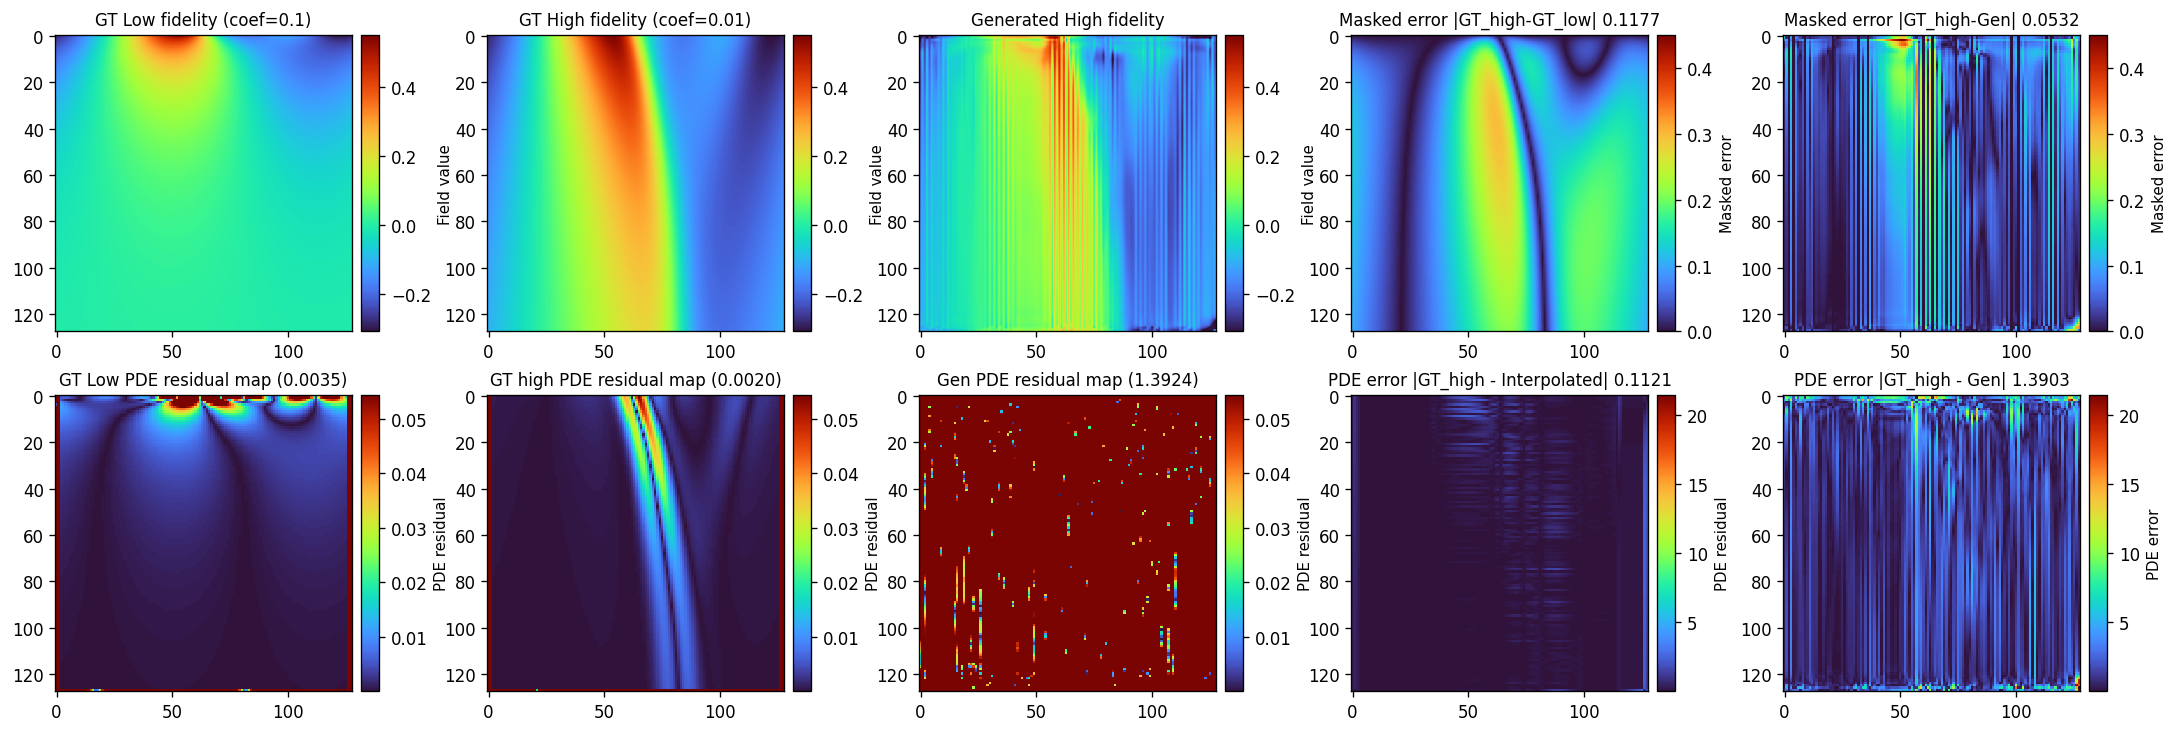

In [17]:
def _to_device_float(x, device):
    if hasattr(x, "to"):
        return x.to(device=device, dtype=torch.float32, non_blocking=True)
    return torch.as_tensor(x, device=device, dtype=torch.float32)

def _to_device_bool(m, device):
    if m is None:
        return None
    if hasattr(m, "to"):
        return m.to(device=device, dtype=torch.bool, non_blocking=True)
    return torch.as_tensor(m, device=device, dtype=torch.bool)

def prepare_unet_input(low_data, high_data, mask_low, mask_high, device):
    low_data  = _to_device_float(low_data, device)
    high_data = _to_device_float(high_data, device)
    mask_low  = _to_device_bool(mask_low, device)
    mask_high = _to_device_bool(mask_high, device)

    B, C, H, W = low_data.shape

    # 1d case: (B,1,T,X) already represented as image (T x X)
    if C == 1:
        if mask_high is not None:
            x1_fixed = (high_data * mask_high).detach()
            low_data  = torch.where(mask_high, x1_fixed, low_data)
            high_data = torch.where(mask_high, x1_fixed, high_data)
        return low_data, high_data, mask_high, "1d"

    # 2d case: input comes as (B,T,X,Y) encoded as (B,C,H,W) with C=T
    # Keep time axis: convert to (B,1,T,X,Y)
    mask_ = mask_high
    if mask_ is not None:
        x1_fixed = (high_data * mask_).detach()
        low_data  = torch.where(mask_, x1_fixed, low_data)
        high_data = torch.where(mask_, x1_fixed, high_data)

    return low_data, high_data, mask_, "2d_time_as_channel"
inference_target = 'test'

sb_object.v_fore.eval()
sb_object.time_embed.eval()
with torch.no_grad():
    x0_fix, x1_fix, mask_fix, mod = prepare_unet_input(x_0, x_1, mask_low, mask_high, 'cuda')
    x_last = fwd_start_from_t(x_0=x0_fix, x_1_fixed=x1_fix, mask=mask_fix, v_m=sb_object.v_fore, t_m=sb_object.time_embed, one_step=True)
plot_result(
        dataA=x0_all[[i]],                  
        dataB=x1_all[[i]],                  
        predict=x_last[[i]], 
        filled=filled_all[[i]],             
        high_resol_coef=high_resol_coef,
        low_resol_coef=low_resol_coef,
        # mask_2d=m1_all[[i]]             
    )